# PERD on toy data: the four questions, end to end

This notebook runs my whole analysis on a small slice of the real data, so you can see each step and try it yourself.
It answers the same four questions as the report (`report/report.pdf`):

1. Is PERD a good model of openness in tissues it never saw?
2. Does it predict the change a perturbation causes?
3. Do TF activity and motif inputs help?
4. Does a model trained on real before/after pairs help?

**Data** (`demo/toy_data/`, 6.8 MB): 150 enhancers with their openness in the 167 ENCODE training samples, the RNA
of the genes they use, and 11 before/after pairs from three perturbation series (A549 + dexamethasone, T-cell
activation, HCT116 degrons). The values are real; only the size is reduced, so the numbers will not match the report.

**Run it:** `pixi install`, then `pixi run notebook` (or `pixi run demo` for the same steps as a script). The full run
takes about 12 minutes on 4 CPUs. The outputs below are saved, so you can read the results without running anything.

**Measure:** NSPE, PERD's normalized squared prediction error. 0 is perfect; 1 means no better than predicting the
average. For a change, the average is about zero, so NSPE > 1 means worse than guessing "no change".

In [1]:
import os
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().resolve()
while not (ROOT / "pixi.toml").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT / "demo"))
import run_demo as rd  # noqa: E402  (the functions used below; same code as `pixi run demo`)

N_JOBS = int(os.environ.get("SLURM_CPUS_PER_TASK", min(8, os.cpu_count() or 1)))
pd.set_option("display.precision", 3)
print("CPUs used:", N_JOBS)

CPUs used: 4


## The toy data

In [2]:
d = rd.load()
print(f"{len(d['enhancers'])} enhancers; ENCODE RNA {d['rna'].shape[0]} genes x {d['rna'].shape[1]} samples; "
      f"{len(d['conditions'])} before/after pairs")
d["enhancers"].head(3)

150 enhancers; ENCODE RNA 6954 genes x 167 samples; 11 before/after pairs


,enhancer_id,chrom,start,end,usable_genes,target_genes,tf_genes
0,chr10:117502907-117503733,chr10,117502907,117503733,"[CTCF, EP300, FAM204A, PDZD8, POLR2A, RAD21, R...","[FAM204A, PDZD8, GC10P117520, LOC105378503]","[CTCF, EP300, POLR2A, RAD21, REST, TFAP2C]"
1,chr10:5851802-5854399,chr10,5851802,5854399,"[ANKRD16, ATF2, ATF3, BATF, BCL11A, BCL3, BCLA...","[ENSG00000226647, LOC105376384, NRBF2P5, ANKRD...","[ATF2, ATF3, BATF, BCL11A, BCL3, BCLAF1, BDP1,..."
2,chr10:6755679-6756666,chr10,6755679,6756666,"[FOS, GDI2, JUN, JUND]","[GDI2, LINP1, LINC00706]","[FOS, JUN, JUND]"


Each enhancer has its PERD inputs (`usable_genes`: its GeneHancer target genes plus the TFs with a ChIP-seq peak in
it), and its openness in the 167 ENCODE samples is the training target. The perturbation pairs list which samples are
before (control) and after (treated):

In [3]:
pd.DataFrame([{"series": c.unit, "pair": c.name, "accessibility samples (before / after)": f"{len(c.acc_control)} / {len(c.acc_treated)}",
               "RNA samples (before / after)": f"{len(c.rna_control)} / {len(c.rna_treated)}"} for c in d["conditions"]])

,series,pair,accessibility samples (before / after),RNA samples (before / after)
0,A549 dexamethasone,A549 dex 2h,4 / 4,4 / 4
1,A549 dexamethasone,A549 dex 6h,4 / 4,4 / 3
2,A549 dexamethasone,A549 dex 12h,4 / 4,4 / 4
3,T-cell activation,T CD4 T,3 / 1,2 / 2
4,T-cell activation,T CD4 memory T,1 / 1,2 / 2
5,T-cell activation,T CD8 T,1 / 2,2 / 2
6,T-cell activation,T naive CD4 T,1 / 2,2 / 2
7,T-cell activation,T naive CD8 T,1 / 1,2 / 2
8,HCT116 BRD4,HCT116 BRD4,2 / 2,2 / 2
9,HCT116 CTCF,HCT116 CTCF,2 / 2,2 / 2


## TF activity

PERD reads a TF's own mRNA. TF activity instead scores each TF from the RNA of its known target genes (CollecTRI network,
univariate linear model as in decoupleR), with genes scaled to the 167 training samples. The control uses the same
method with randomly chosen target genes.

In [4]:
t0 = time.time()
act = rd.activities(d)
print(f"{act['encode'].shape[0]} TFs scored for {act['encode'].shape[1]} ENCODE samples and {act['pert'].shape[1]} perturbation samples ({time.time() - t0:.0f} s)")
versions = rd.variants(d, act)   # PERD-RF and its input versions
list(versions)

766 TFs scored for 167 ENCODE samples and 47 perturbation samples (45 s)


['PERD-RF (RNA only)',
 '+ shuffled activity (control)',
 '+ TF activity',
 '+ motifs',
 '+ TF activity + motifs']

## Questions 1 and 3a: unseen tissues

The 167 samples belong to 75 tissue or cell types. In 5-fold cross-validation by type, each sample is predicted by
models that never saw its tissue. I compare this with PERD's random 110/57 split, and the input versions with each
other.

In [5]:
t0 = time.time()
q1 = rd.q1_q3_unseen_tissues(d, versions, N_JOBS)
print(f"{(time.time() - t0) / 60:.1f} min")
q1[["version", "scheme", "nspe_per_cell_median", "cross_cell_pearson_median", "cross_enhancer_pearson_median"]]

  unseen tissues | PERD-RF (RNA only): per-cell NSPE 0.255


  unseen tissues | + shuffled activity (control): per-cell NSPE 0.235


  unseen tissues | + TF activity: per-cell NSPE 0.241


  unseen tissues | + motifs: per-cell NSPE 0.224


  unseen tissues | + TF activity + motifs: per-cell NSPE 0.215


8.9 min


,version,scheme,nspe_per_cell_median,cross_cell_pearson_median,cross_enhancer_pearson_median
0,PERD-RF (RNA only),random 110/57 split,0.247,0.555,0.896
1,PERD-RF (RNA only),tissue held out,0.255,0.527,0.888
2,+ shuffled activity (control),tissue held out,0.235,0.556,0.892
3,+ TF activity,tissue held out,0.241,0.577,0.890
4,+ motifs,tissue held out,0.224,0.577,0.897
5,+ TF activity + motifs,tissue held out,0.215,0.597,0.899


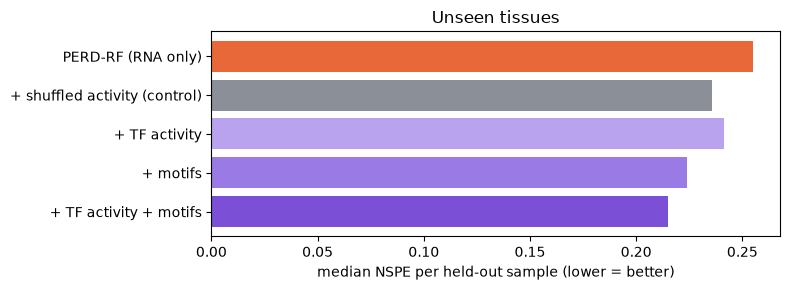

In [6]:
held = q1[q1["scheme"] == "tissue held out"]
fig, ax = plt.subplots(figsize=(8, 3))
ax.barh(held["version"][::-1], held["nspe_per_cell_median"][::-1], color=["#7B4FD6", "#9A7BE6", "#B9A3EE", "#8A8F98", "#E8683A"])
ax.set_xlabel("median NSPE per held-out sample (lower = better)")
ax.set_title("Unseen tissues")
plt.tight_layout()

## Questions 2 and 3b: the perturbations

For each pair, every version is fitted on the 167 ENCODE samples and predicts openness from the RNA before and after;
the predicted change is after − before. I score the before side, the after side, and the change.

In [7]:
t0 = time.time()
q2, frozen_change = rd.q2_q3_perturbations(d, versions, N_JOBS)
print(f"{(time.time() - t0) / 60:.1f} min")
q2.groupby(["version", "unit"], sort=False)[["nspe_before", "nspe_after", "nspe_change"]].median()

  perturbations | PERD-RF (RNA only): median change NSPE 1.35


  perturbations | + TF activity: median change NSPE 1.23


  perturbations | + motifs: median change NSPE 1.30


  perturbations | + TF activity + motifs: median change NSPE 1.32


1.5 min


nspe_before  nspe_after  \
version                unit                                          
PERD-RF (RNA only)     A549 dexamethasone        0.452       0.408   
                       T-cell activation         0.303       0.390   
                       HCT116 BRD4               0.374       0.351   
                       HCT116 CTCF               0.374       0.411   
                       HCT116 MED14              0.360       0.363   
+ TF activity          A549 dexamethasone        0.454       0.418   
                       T-cell activation         0.304       0.390   
                       HCT116 BRD4               0.341       0.358   
                       HCT116 CTCF               0.359       0.368   
                       HCT116 MED14              0.328       0.333   
+ motifs               A549 dexamethasone        0.401       0.387   
                       T-cell activation         0.283       0.382   
                       HCT116 BRD4               0.332       0.331   
                       HCT116 CTCF               0.357       0.372   
                       HCT116 MED14              0.335       0.341   
+ TF activity + motifs A549 dexamethasone        0.423       0.391   
                       T-cell activation         0.281       0.372   
                       HCT116 BRD4               0.315       0.340   
                       HCT116 CTCF               0.342       0.341   
                       HCT116 MED14              0.319       0.335   

                                           nspe_change  
version                unit                             
PERD-RF (RNA only)     A549 dexamethasone        1.589  
                       T-cell activation         1.084  
                       HCT116 BRD4               2.945  
                       HCT116 CTCF               1.228  
                       HCT116 MED14              1.352  
+ TF activity          A549 dexamethasone        1.318  
                       T-cell activation         1.125  
                       HCT116 BRD4               1.888  
                       HCT116 CTCF               1.134  
                       HCT116 MED14              1.234  
+ motifs               A549 dexamethasone        1.644  
                       T-cell activation         1.172  
                       HCT116 BRD4               1.695  
                       HCT116 CTCF               1.117  
                       HCT116 MED14              1.299  
+ TF activity + motifs A549 dexamethasone        1.458  
                       T-cell activation         1.190  
                       HCT116 BRD4               1.558  
                       HCT116 CTCF               1.103  
                       HCT116 MED14              1.324

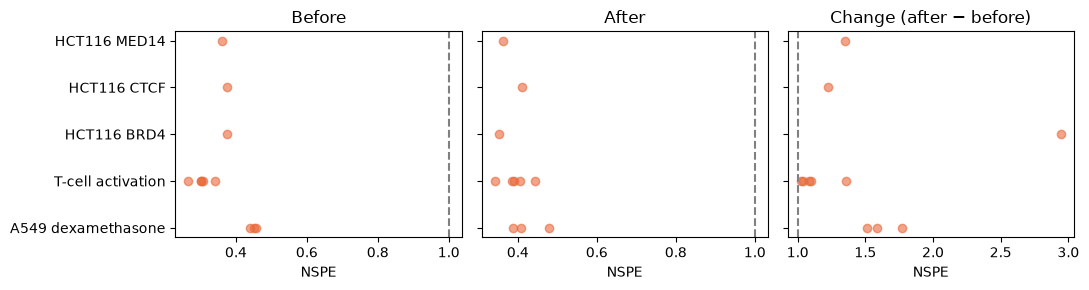

In [8]:
frozen = q2[q2["version"] == "PERD-RF (RNA only)"]
fig, axes = plt.subplots(1, 3, figsize=(11, 3), sharey=True)
for ax, col, title in zip(axes, ["nspe_before", "nspe_after", "nspe_change"], ["Before", "After", "Change (after − before)"]):
    ax.scatter(frozen[col], frozen["unit"], color="#E8683A", alpha=0.6)
    ax.axvline(1, ls="--", color="grey")
    ax.set_title(title)
    ax.set_xlabel("NSPE")
plt.tight_layout()

PERD-RF predicts each side well (NSPE well below 1) but the change badly (around or above 1), the same pattern as
in the full data.

## Question 4: training on real before/after pairs

The pair model is one random forest that learns the change directly. Each row is one enhancer in one pair; the inputs
are the treatment's TF-activity change matched to the enhancer's motifs and ChIP binding, the RNA change of its target
genes, its openness before treatment and five fixed properties. Leave one perturbation out: train on the others,
predict the held-out one. The control is the same forest with only the starting openness and the fixed properties.
(With so few rows, the toy run uses a smaller minimum leaf size than the full run.)

In [9]:
t0 = time.time()
q4 = rd.q4_pair_model(d, act, frozen_change, N_JOBS)
print(f"{(time.time() - t0) / 60:.1f} min")
q4.groupby(["unit", "model"])["nspe_change"].median().unstack()

0.4 min


model,PERD-RF (RNA only),Pair model,Starting openness only (control)
unit,,,
A549 dexamethasone,1.589,1.068,2.164
HCT116 BRD4,2.945,1.054,1.316
HCT116 CTCF,1.228,1.001,1.443
HCT116 MED14,1.352,1.090,1.053
T-cell activation,1.084,1.038,1.028


## What to take from the toy run

The toy data are far smaller than the real analysis (150 instead of 120,100 enhancers, 5 instead of 16
perturbations), so the exact numbers move around, especially for question 4. The full results, on all enhancers and
all 40 pairs, are in `report/report.pdf` and `results/tables/`, and the scripts that produce them are listed in the
README.